# Phase 2 - The Market Simulator & the Avellaneda-Stoikov Baseline

We now have a market to trade in and the first agent to trade in it. Two things to establish:

1. **The environment is honest** - the fill / margin tradeoff that defines market making *emerges* from the matching engine, rather than being assumed.
2. **The Avellaneda-Stoikov baseline works** - a closed-form, inventory-aware quoter that the reinforcement-learning agents will have to beat.

### The model the agent lives in
- **State**: `[inventory, book imbalance, spread, time-remaining, recent return, realised vol]`
- **Action**: a discrete `(bid_offset, ask_offset)` in ticks - asymmetry lets it *skew* against inventory.
- **Reward**: `dWealth - inventory_penalty * q^2`, with a forced unwind at the horizon.

### The Avellaneda-Stoikov rule
Reservation (inventory-adjusted) price and optimal spread:
$$ r(s,t) = s - q\,\gamma\,\sigma^2\,(T-t), \qquad \delta = \gamma\sigma^2 (T-t) + \tfrac{2}{\gamma}\ln\!\left(1+\tfrac{\gamma}{\kappa}\right) $$
quoting `bid = r - delta/2`, `ask = r + delta/2`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from quant_mm.sim import MarketMakingEnv, MMEnvConfig
from quant_mm.agents import AvellanedaStoikovAgent, ASConfig, FixedSymmetricAgent, RandomAgent
from quant_mm.eval import run_episode, evaluate, summary_table

cfg = MMEnvConfig()
env = MarketMakingEnv(cfg)
print('action space:', env.action_space, '| obs space:', env.observation_space)

action space: Discrete(16) | obs space: Box(-10.0, 10.0, (6,), float32)


## 1. The fill/margin tradeoff is emergent
We quote both sides at a fixed offset and measure how often we get filled. If the engine economics are right, quoting **wider** must fill **less often** - the empirical analogue of the Avellaneda-Stoikov arrival intensity $\lambda(\delta)=A e^{-\kappa\delta}$.

avg fills by offset: {1: 844.4, 2: 686.0, 3: 510.4, 4: 323.4}
fitted intensity decay kappa = 0.318 per tick  (= 32 per price unit)


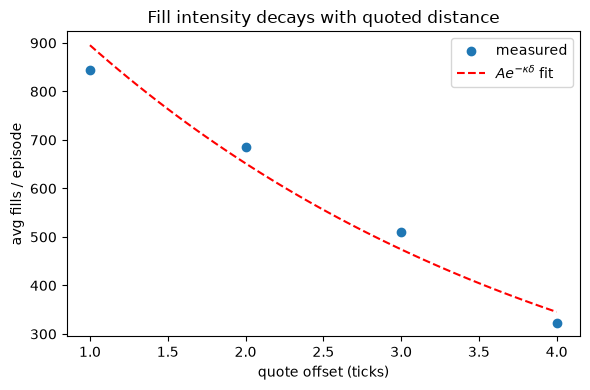

In [2]:
def avg_fills_at_offset(off, episodes=40):
    a = (off-1)*cfg.n_offsets + (off-1)
    fills = []
    for ep in range(episodes):
        env.reset(seed=ep); f=0; done=False
        while not done:
            _,_,term,trunc,info = env.step(a); f += info['fills']; done=term or trunc
        fills.append(f)
    return np.mean(fills)

offsets = np.array([1,2,3,4])
fills = np.array([avg_fills_at_offset(o) for o in offsets])
# Fit log-linear decay: ln(fills) = a - kappa*offset  ->  recover kappa (per tick)
slope, intercept = np.polyfit(offsets, np.log(fills), 1)
kappa_ticks = -slope
print('avg fills by offset:', dict(zip(offsets.tolist(), np.round(fills,1).tolist())))
print(f'fitted intensity decay kappa = {kappa_ticks:.3f} per tick  (= {kappa_ticks/cfg.tick:.0f} per price unit)')

fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(offsets, fills, color='tab:blue', zorder=3, label='measured')
xx = np.linspace(1,4,50)
ax.plot(xx, np.exp(intercept + slope*xx), 'r--', label=f'$A e^{{-\\kappa\\delta}}$ fit')
ax.set_xlabel('quote offset (ticks)'); ax.set_ylabel('avg fills / episode')
ax.set_title('Fill intensity decays with quoted distance'); ax.legend(); plt.tight_layout(); plt.show()

## 2. The reservation price skews against inventory
This is the core of Avellaneda-Stoikov: when long, the maker quotes around a price *below* mid (keen to sell, shy to buy); when short, *above* mid. We visualise the reservation price and the resulting bid/ask offsets vs inventory.

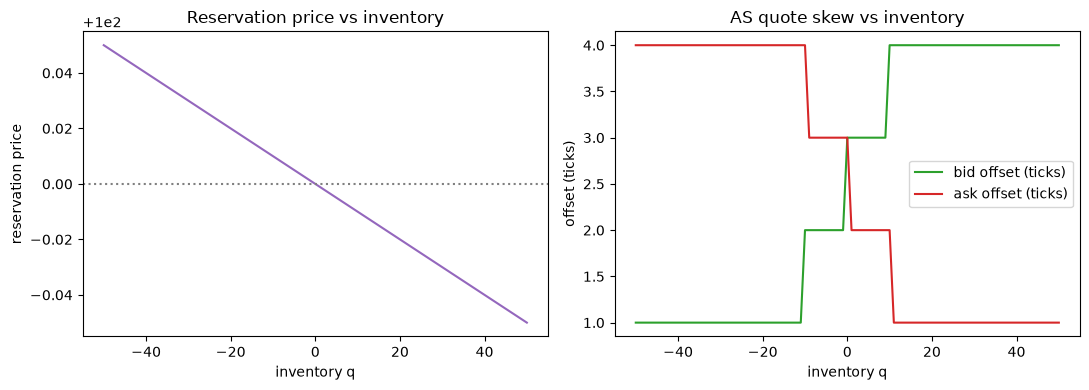

When long (q>0): bid is quoted further out, ask is pulled in -> the book leans to sell down the position.


In [3]:
as_cfg = ASConfig(gamma=0.1, kappa=40.0)
agent = AvellanedaStoikovAgent(cfg, as_cfg)

s = cfg.s0
T_minus_t = cfg.horizon * 0.5   # mid-episode
qs = np.arange(-cfg.max_inventory, cfg.max_inventory+1)
res_price = s - qs * as_cfg.gamma * cfg.sigma**2 * T_minus_t

# Decode the agent's chosen bid/ask offsets as a function of inventory.
bid_off, ask_off = [], []
for q in qs:
    obs = np.array([q/cfg.max_inventory, 0, 0, 0.5, 0, 1], dtype=np.float32)
    a = agent.act(obs)
    b, k = divmod(a, cfg.n_offsets)
    bid_off.append(b+1); ask_off.append(k+1)

fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(qs, res_price, color='tab:purple'); axes[0].axhline(s, ls=':', color='gray')
axes[0].set_xlabel('inventory q'); axes[0].set_ylabel('reservation price'); axes[0].set_title('Reservation price vs inventory')
axes[1].plot(qs, bid_off, label='bid offset (ticks)', color='tab:green')
axes[1].plot(qs, ask_off, label='ask offset (ticks)', color='tab:red')
axes[1].set_xlabel('inventory q'); axes[1].set_ylabel('offset (ticks)'); axes[1].set_title('AS quote skew vs inventory'); axes[1].legend()
plt.tight_layout(); plt.show()
print('When long (q>0): bid is quoted further out, ask is pulled in -> the book leans to sell down the position.')

## 3. One episode of the Avellaneda-Stoikov agent
Inventory should stay bounded and mean-reverting around zero; wealth should grind upward.

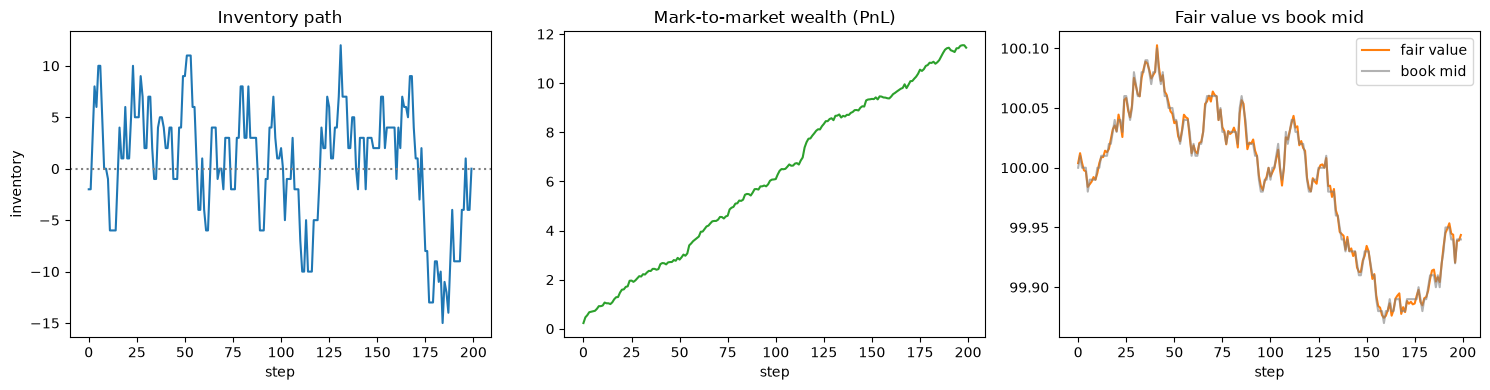

terminal PnL = 11.445, max |inventory| = 15


In [4]:
ep = run_episode(env, agent, seed=42)
fig, axes = plt.subplots(1, 3, figsize=(15,4))
axes[0].plot(ep.inventory, color='tab:blue'); axes[0].axhline(0, ls=':', color='gray')
axes[0].set_title('Inventory path'); axes[0].set_xlabel('step'); axes[0].set_ylabel('inventory')
axes[1].plot(ep.wealth, color='tab:green'); axes[1].set_title('Mark-to-market wealth (PnL)'); axes[1].set_xlabel('step')
axes[2].plot(ep.fair, color='tab:orange', label='fair value'); axes[2].plot(ep.mid, color='tab:gray', alpha=0.6, label='book mid')
axes[2].set_title('Fair value vs book mid'); axes[2].set_xlabel('step'); axes[2].legend()
plt.tight_layout(); plt.show()
print(f'terminal PnL = {ep.terminal_pnl:.3f}, max |inventory| = {max(abs(np.array(ep.inventory)))}')

## 4. Head-to-head: AS vs naive policies
The number that matters is **Sharpe** (risk-adjusted PnL). A good inventory-aware maker should earn comparable PnL to an aggressive fixed policy but at far lower inventory risk - i.e. a much higher Sharpe.

In [5]:
agents = {
    'Random': RandomAgent(cfg, seed=0),
    'Fixed(1 tick)': FixedSymmetricAgent(cfg, 1),
    'Fixed(3 ticks)': FixedSymmetricAgent(cfg, 3),
    'Avellaneda-Stoikov': AvellanedaStoikovAgent(cfg, as_cfg),
}
results = {name: evaluate(env, ag, n_episodes=150) for name, ag in agents.items()}
print(summary_table(results))

agent                             pnl_mean             pnl_std              sharpe            win_rate  mean_abs_inventory           avg_fills
----------------------------------------------------------------------------------------------------------------------------------------------
Random                              8.8843              3.9142              2.2697              0.9733             19.6773            586.2200
Fixed(1 tick)                       4.2634              3.6600              1.1649              0.8933             19.8288            839.4200
Fixed(3 ticks)                     11.4872              3.7123              3.0944              0.9867             19.4275            504.0200
Avellaneda-Stoikov                 10.5396              1.6886              6.2415              1.0000              6.6248            593.2200


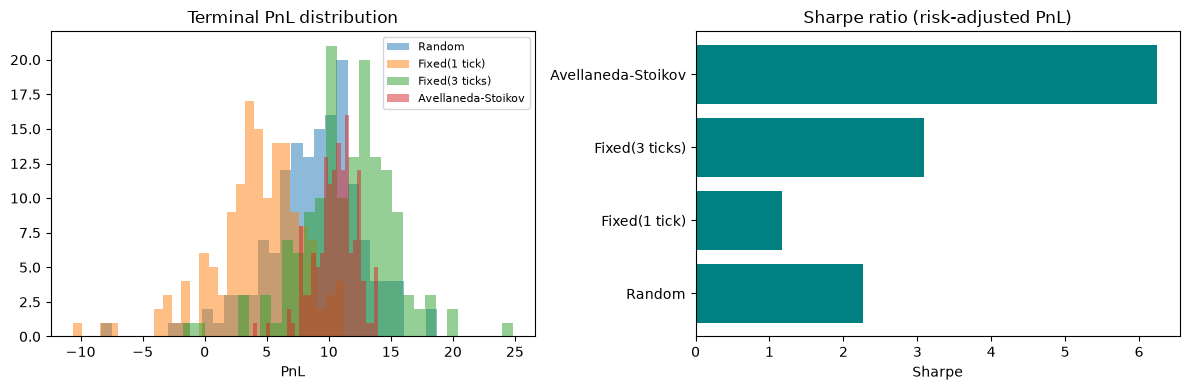

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for name, r in results.items():
    axes[0].hist(r['pnls'], bins=30, alpha=0.5, label=name)
axes[0].set_title('Terminal PnL distribution'); axes[0].set_xlabel('PnL'); axes[0].legend(fontsize=8)
names = list(results)
sharpes = [results[n]['sharpe'] for n in names]
axes[1].barh(names, sharpes, color='teal'); axes[1].set_title('Sharpe ratio (risk-adjusted PnL)'); axes[1].set_xlabel('Sharpe')
plt.tight_layout(); plt.show()

## 5. Adverse selection is real in this market
As we raise the fraction of **informed** flow, getting filled becomes more dangerous (you trade right before the price moves against you). A naive tight quoter should suffer more than the inventory-aware AS agent.

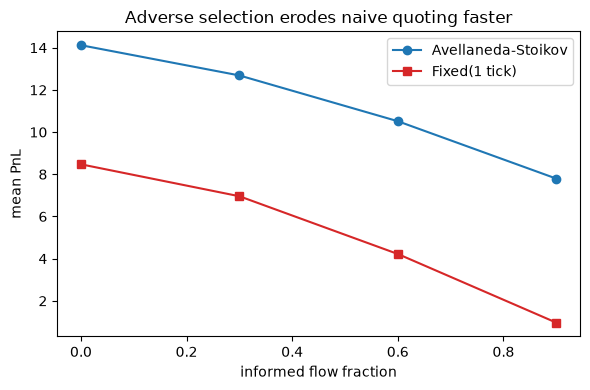

In [7]:
ratios = [0.0, 0.3, 0.6, 0.9]
as_pnl, fixed_pnl = [], []
for ir in ratios:
    e = MarketMakingEnv(MMEnvConfig(informed_ratio=ir))
    as_pnl.append(evaluate(e, AvellanedaStoikovAgent(e.cfg, as_cfg), n_episodes=80)['pnl_mean'])
    fixed_pnl.append(evaluate(e, FixedSymmetricAgent(e.cfg, 1), n_episodes=80)['pnl_mean'])

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(ratios, as_pnl, 'o-', label='Avellaneda-Stoikov', color='tab:blue')
ax.plot(ratios, fixed_pnl, 's-', label='Fixed(1 tick)', color='tab:red')
ax.set_xlabel('informed flow fraction'); ax.set_ylabel('mean PnL'); ax.set_title('Adverse selection erodes naive quoting faster'); ax.legend()
plt.tight_layout(); plt.show()

---
**Takeaway.** The environment reproduces the real economics of market making - an emergent exponential fill intensity, genuine adverse selection - and the Avellaneda-Stoikov baseline manages inventory to deliver the best risk-adjusted PnL of any rule so far. **This Sharpe is the bar the RL agent must clear.**

Next: **Phase 3** - a DQN, implemented from scratch, that learns a quoting policy directly from experience.